# Tutorial 2: Designing searches

PMC searches the **full text** of every article. That is powerful, but a plain search such as `gut microbiome frailty` matches any article that mentions those words anywhere, including in its reference list. Most of what it returns is about something else.

This tutorial compares five versions of the same question, from loose to strict, and measures each one three ways:

1. **Size**: how many articles PMC finds.
2. **Precision**: how many of the newest results are actually about the topic.
3. **Availability**: how many of them can be downloaded as full text.

It uses the low-level building blocks, `esearch_pmc` and `efetch_pmc`, plus one raw E-utilities call. It takes about a minute.

In [1]:
import os
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import tutorial_utils as tu

tu.setup()
tu.style()

from pubmed_stream import RateLimiter, create_session, efetch_pmc, esearch_pmc

API_KEY = os.environ.get("NCBI_API_KEY")
session = create_session("pubmed-stream-tutorial")
limiter = RateLimiter(0.1 if API_KEY else 0.34)   # NCBI allows 10 requests/s with a key, 3 without

## 1. Five versions of one question

Each version adds one restriction. PMC's field tags work like PubMed's: `[Title]`, `[Abstract]`, `[Title/Abstract]`, quotes for phrases, and filters such as `"open access"[filter]`.

In [2]:
VARIANTS = {
    "Words anywhere": "gut microbiome frailty",
    "Phrase anywhere": '"gut microbiome" AND frailty',
    "Title or abstract": '("gut microbiome"[Title/Abstract] OR "gut microbiota"[Title/Abstract]) AND frailty[Title/Abstract]',
    "Microbiota in title": '"gut microbiota"[Title] AND frailty[Title/Abstract]',
    "+ open access": '"gut microbiota"[Title] AND frailty[Title/Abstract] AND "open access"[filter]',
}

SAMPLE = 20
results = {}
for label, query in VARIANTS.items():
    ids, total = esearch_pmc(query, SAMPLE, API_KEY, session, limiter)
    results[label] = {"query": query, "total": total, "ids": ids}
    print(f"{label:20} {total:>8,} articles")

Words anywhere          7,587 articles


Phrase anywhere         6,092 articles


Title or abstract         194 articles
Microbiota in title        66 articles


+ open access              61 articles


## 2. How precise is each version?

To judge precision, fetch the titles of the newest 20 results of each version with the E-utilities **ESummary** endpoint, and count a result as on topic when its title mentions both the gut microbiome or microbiota and frailty. A title test is strict, so it underestimates precision a little, but it is the same test for every version.

In [3]:
ESUMMARY = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/esummary.fcgi"

def titles(pmc_ids):
    params = {"db": "pmc", "id": ",".join(pmc_ids), "retmode": "json"}
    if API_KEY:
        params["api_key"] = API_KEY
    for attempt in range(3):   # NCBI answers a burst of requests with a rate-limit error
        limiter.wait()
        response = session.get(ESUMMARY, params=params, timeout=60)
        if response.ok and "result" in response.json():
            data = response.json()["result"]
            return [data[i]["title"] for i in data["uids"]]
        time.sleep(2 * (attempt + 1))
    raise RuntimeError(f"ESummary failed: {response.status_code} {response.text[:200]}")

def on_topic(title):
    return bool(re.search(r"microbio|gut flora", title, re.I)) and bool(re.search(r"frail", title, re.I))

for label, r in results.items():
    r["titles"] = titles(r["ids"])
    r["precision"] = sum(map(on_topic, r["titles"])) / len(r["titles"]) if r["titles"] else 0

print("Newest titles for the loosest version:")
for title in results["Words anywhere"]["titles"][:5]:
    print("  -", tu.short(title, 100))

Newest titles for the loosest version:
  - The complicated relationship between inflammation and metabolic dysfunction.
  - Biological age in the meta omics era: Integrating physical activity, sleep, and diet to reshape pat…
  - Bile acid metabolism and signaling in human and animal health: A One Health perspective.
  - The microbiome-metabolite-vaccine axis: context-dependent modulators of immunogenicity and durabili…
  - Food-based formula modulates gut microbial homeostasis and inflammatory responses following LPS cha…


The loosest search finds tens of thousands of articles, but almost none of its newest results are about the question. Each restriction shrinks the result and raises its precision. The two panels share the same versions, so read them side by side:

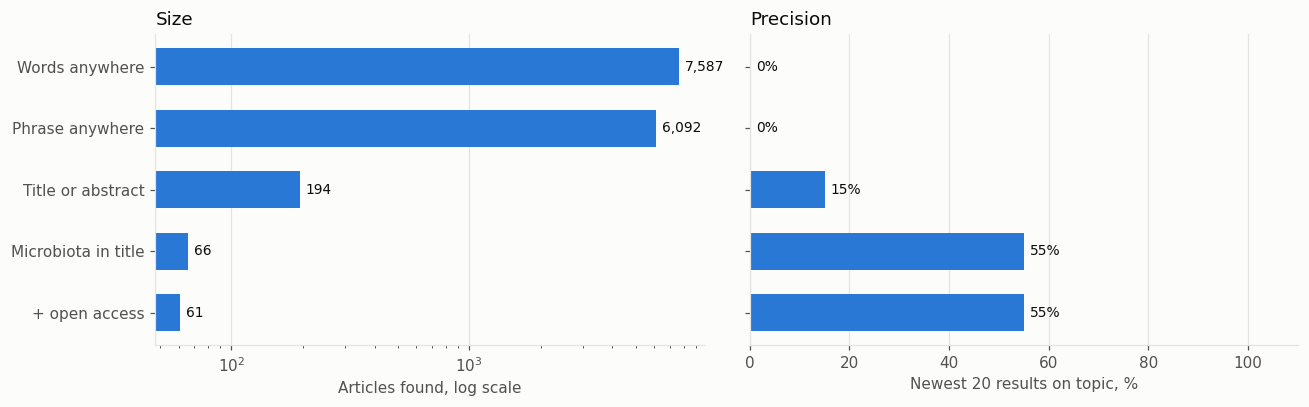

In [4]:
labels = list(results)[::-1]
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)

bars = left.barh(labels, [results[l]["total"] for l in labels], color=tu.BLUE, height=0.6)
left.set_xscale("log")
tu.bar_labels(left, bars, fmt="{:,.0f}", horizontal=True)
tu.gridlines(left, "x")
left.set_xlabel("Articles found, log scale")
left.set_title("Size")

bars = right.barh(labels, [100 * results[l]["precision"] for l in labels], color=tu.BLUE, height=0.6)
tu.bar_labels(right, bars, fmt="{:.0f}%", horizontal=True, zero=True)
right.set_xlim(0, 110)
tu.gridlines(right, "x")
right.set_xlabel(f"Newest {SAMPLE} results on topic, %")
right.set_title("Precision")
plt.tight_layout()
plt.show()

## 3. Can the results be downloaded?

PMC lists many articles whose publishers do not allow the full text to be downloaded as XML. `efetch_pmc` reports those as *unavailable*. The open-access filter restricts a search to articles that can always be downloaded. Here are the newest eight results of the last two versions:

In [5]:
availability = []
for label in ["Microbiota in title", "+ open access"]:
    for pmc_id in results[label]["ids"][:8]:
        ok, status = efetch_pmc(pmc_id, Path("availability") / label.strip("+ ").replace(" ", "_"),
                                "text", API_KEY, session, limiter)
        availability.append({"search": label, "pmc_id": pmc_id,
                             "status": "exists" if status == "exists" else status})

table = pd.DataFrame(availability)
table.groupby(["search", "status"]).size().unstack(fill_value=0)

status,success,unavailable
search,,
+ open access,8,0
Microbiota in title,6,2


## 4. A checklist for good searches

| Technique | Example | Effect |
|---|---|---|
| Put the core concept in the title | `"gut microbiota"[Title]` | Largest gain in precision |
| Restrict the rest to title and abstract | `frailty[Title/Abstract]` | Drops passing mentions in the body and references |
| Quote multi-word terms | `"gut microbiome"` | Keeps the words together |
| Cover synonyms with `OR` | `("gut microbiome" OR "gut microbiota")` | Recovers recall lost to strict fields |
| Restrict to open access | `AND "open access"[filter]` | Every result can be downloaded |
| Limit the years | `AND 2020:2026[pdat]` | Focuses on recent work |

Two habits help most. Check the size of a search with `esearch_pmc` before downloading, and read a sample of titles before trusting it.

**Next:** tutorial 3 runs a whole list of searches to build a literature-review corpus.

In [6]:
session.close()